# Lab: Build a dense variational autoencoder for faces

**Time:** 90–120 minutes  
**Prerequisites:** PyTorch, linear layers, probability basics, and gradient descent

In this lab you will turn an image into a *distribution* in latent space, sample from
that distribution with the reparameterization trick, and train a decoder using the
VAE objective. The network is deliberately fully connected: convolution is useful
for images, but it is not what makes a model a VAE.

By the end, you should be able to:

- distinguish a deterministic autoencoder from a VAE;
- parameterize $q_\phi(z\mid x)$ with $\mu$ and $\log\sigma^2$;
- implement $z=\mu+\sigma\odot\epsilon$ without breaking backpropagation;
- combine reconstruction and KL-divergence terms; and
- generate new faces by sampling $z\sim\mathcal N(0,I)$.


## 1. Environment and LFW data (10 minutes)

This notebook runs both on Kaggle and locally.

**On Kaggle:** create a notebook, choose **Add Input**, search for `LFW Dataset`, and
attach the dataset whose mounted folder is `/kaggle/input/lfw-dataset`. Upload this
notebook or open it from the course repository, then choose a GPU accelerator if one
is available. No path edit should be necessary.

**Locally:** download and extract LFW so the directory contains person folders and
`.jpg` files. Then either:

1. set the environment variable `LFW_DATASET_PATH` to the extracted directory; or
2. edit `LOCAL_DATASET_PATH` in the next cell.

The path may point either directly to `lfw-deepfunneled` or to a parent directory;
the discovery code searches below it. The notebook fails early with a useful message
if no images are found.


In [1]:
# Kaggle images normally include these packages. For a minimal local environment:
# %pip install torch torchvision matplotlib pandas scikit-learn pillow

import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 45
CHANNELS = 3
INPUT_DIM = CHANNELS * IMAGE_SIZE * IMAGE_SIZE
LATENT_DIM = 100
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 1e-3
BETA = 1.0
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

# Change only this line for a local setup if LFW_DATASET_PATH is not set.
LOCAL_DATASET_PATH = Path("lfw")

print(f"Running on {DEVICE}")


Running on cuda


In [2]:
def resolve_lfw_root():
    env_path = os.environ.get("LFW_DATASET_PATH")
    candidates = []
    if env_path:
        candidates.append(Path(env_path).expanduser())
    if Path("/kaggle/input").exists():
        candidates.extend([
            Path("/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled"),
            Path("/kaggle/input/lfw-dataset"),
        ])
    candidates.extend([
        LOCAL_DATASET_PATH.expanduser(),
        Path("lfw-deepfunneled"),
    ])

    for root in candidates:
        if root.exists() and next(root.rglob("*.jpg"), None) is not None:
            return root
    checked = "\n".join(f"  - {path}" for path in candidates)
    raise FileNotFoundError(
        "No LFW .jpg files were found. Attach lfw-dataset on Kaggle, set "
        "LFW_DATASET_PATH, or edit LOCAL_DATASET_PATH. Checked:\n" + checked
    )


DATASET_ROOT = resolve_lfw_root()
image_paths = sorted(DATASET_ROOT.rglob("*.jpg"))
image_df = pd.DataFrame({
    "path": image_paths,
    "person": [path.parent.name for path in image_paths],
})

# Preserve the original notebook's balancing choice: remove identities with 25+
# photographs so a few celebrities do not dominate reconstruction training.
image_df = image_df.groupby("person", group_keys=False).filter(lambda rows: len(rows) < 25)
image_df = image_df.reset_index(drop=True)

print(f"Dataset root: {DATASET_ROOT}")
print(f"Using {len(image_df):,} images from {image_df['person'].nunique():,} people")
image_df.head()


Dataset root: lfw
Using 10,645 images from 5,707 people


,path,person
0,lfw/AJ_Cook/AJ_Cook_0001.jpg,AJ_Cook
1,lfw/AJ_Lamas/AJ_Lamas_0001.jpg,AJ_Lamas
2,lfw/Aaron_Eckhart/Aaron_Eckhart_0001.jpg,Aaron_Eckhart
3,lfw/Aaron_Guiel/Aaron_Guiel_0001.jpg,Aaron_Guiel
4,lfw/Aaron_Patterson/Aaron_Patterson_0001.jpg,Aaron_Patterson


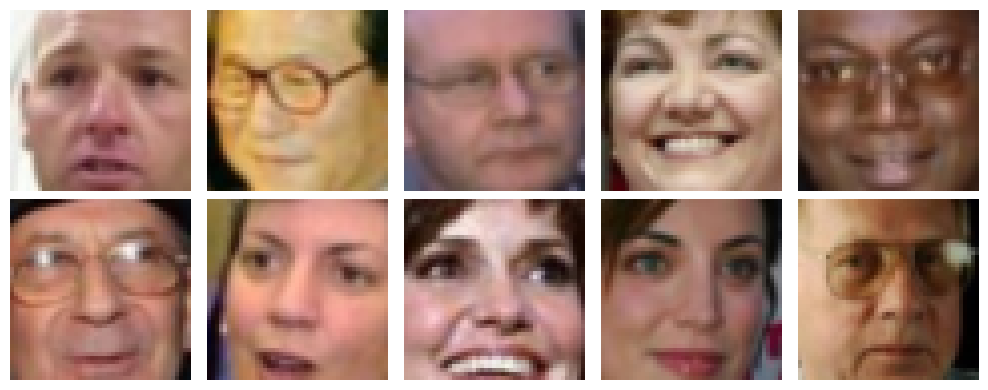

In [3]:
class FaceDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        path = self.dataframe.loc[index, "path"]
        with Image.open(path) as image:
            image = image.convert("RGB")
            # LFW deep-funneled images are 250x250. This reproduces the original
            # notebook's central crop while remaining safe for other image sizes.
            width, height = image.size
            margin_x = min(80, max(0, (width - 1) // 3))
            margin_y = min(80, max(0, (height - 1) // 3))
            image = image.crop((margin_x, margin_y, width - margin_x, height - margin_y))
            return self.transform(image)


transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),  # pixel values in [0, 1]
])

train_df, val_df = train_test_split(image_df, test_size=0.2, random_state=SEED)
train_dataset = FaceDataset(train_df, transform)
val_dataset = FaceDataset(val_df, transform)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
train_loader = DataLoader(train_dataset, shuffle=True, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)

faces = next(iter(train_loader))
assert faces.ndim == 4 and faces.shape[1:] == (3, 45, 45)
assert 0 <= faces.min() and faces.max() <= 1

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(faces[:10], axes.flat):
    axis.imshow(face.permute(1, 2, 0))
    axis.axis("off")
plt.tight_layout()


## 2. From autoencoder to VAE (10 minutes)

A deterministic autoencoder maps $x$ to one vector $z$. A VAE encoder instead
describes a diagonal Gaussian approximate posterior:

$$q_\phi(z\mid x)=\mathcal N\left(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))\right).$$

We predict `logvar` rather than variance because it may take any real value and is
numerically convenient. For a batch of `N` images and `LATENT_DIM = 100`, answer:

1. What are the shapes of `mu`, `logvar`, and `z`?
2. Why must the final `mu` and `logvar` layers have no ReLU?
3. Why does directly drawing `z` from a distribution parameterized by the encoder
   make ordinary backpropagation difficult?

Write your answers in a new Markdown cell.


### Section 2 Answers: From Autoencoder to VAE

1. **What are the shapes of `mu`, `logvar`, and `z`?**
   - `mu`: `(N, LATENT_DIM)` = `(N, 100)`
   - `logvar`: `(N, LATENT_DIM)` = `(N, 100)`
   - `z`: `(N, LATENT_DIM)` = `(N, 100)`
   For a mini-batch of $N$ images, the encoder outputs an $N \times 100$ matrix of mean vectors $\mu$ and an $N \times 100$ matrix of log-variance vectors $\log\sigma^2$. The sampled latent code $z$ has the exact same shape $(N, 100)$, where each coordinate $z_j$ is sampled from $\mathcal{N}(\mu_j, \sigma_j^2)$.

2. **Why must the final `mu` and `logvar` layers have no ReLU?**
   - **`mu_head`:** The posterior mean $\mu$ represents coordinates in latent space $\mathbb{R}^{D}$. Because latent features can be arbitrarily positive, negative, or zero, $\mu$ must be unconstrained in $(-\infty, +\infty)$. A ReLU activation would restrict $\mu \ge 0$, trapping all latent representations in the non-negative orthant.
   - **`logvar_head`:** The head predicts $\log\sigma^2$, which parameterizes variance $\sigma^2 = \exp(\log\sigma^2) > 0$. When the model needs to be confident and have small variance $\sigma^2 < 1$, the logarithm $\log\sigma^2$ must be negative ($-\infty < \log\sigma^2 < 0$). Applying ReLU would enforce $\log\sigma^2 \ge 0$, which implies $\sigma^2 = \exp(\log\sigma^2) \ge 1$ (standard deviation $\sigma \ge 1$). This would prevent the encoder from predicting confident/concentrated posterior distributions.

3. **Why does directly drawing `z` from a distribution parameterized by the encoder make ordinary backpropagation difficult?**
   - Directly sampling $z \sim \mathcal{N}(\mu, \sigma^2)$ is a non-deterministic stochastic operation. Standard backpropagation requires continuous, deterministic operations where the derivative $\frac{\partial z}{\partial \theta}$ is well-defined. Because a random sampling node introduces stochastic variance without an analytical gradient path to $\mu$ and $\sigma$, gradients from the loss cannot backpropagate through the sample to update the encoder.
   - The **reparameterization trick** solves this by separating the stochasticity into an independent parameter-free noise source $\epsilon \sim \mathcal{N}(0, I)$ and expressing $z = \mu + \sigma \odot \epsilon$. This makes $z$ a deterministic, differentiable function of $\mu$ and $\sigma$, allowing gradients from the reconstruction loss to flow seamlessly back through the encoder.

## 3. Implement the probabilistic encoder (25 minutes)

**TODO 1:** Add two linear heads that map the shared 1000-unit representation to
`LATENT_DIM`: one for `mu` and one for `logvar`.

**TODO 2:** Implement the reparameterization trick. Compute
$\sigma=\exp(\tfrac12\log\sigma^2)$, draw $\epsilon$ with `torch.randn_like`, and
return $\mu+\sigma\epsilon$.

**TODO 3:** Complete `forward`: encode, sample, decode, and return
`reconstruction, mu, logvar`. The decoder returns probabilities in `[0, 1]`, so its
last operation is a sigmoid.


In [4]:
class DenseFaceVAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1500),
            nn.ReLU(),
            nn.Linear(1500, 1000),
            nn.ReLU(),
        )

        # TODO 1: define self.mu_head and self.logvar_head.

        self.mu_head = nn.Linear(1000, latent_dim)
        self.logvar_head = nn.Linear(1000, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 1000),
            nn.ReLU(),
            nn.Linear(1000, 1500),
            nn.ReLU(),
            nn.Linear(1500, input_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        features = self.encoder(x.flatten(start_dim=1))
        return self.mu_head(features), self.logvar_head(features)

    def reparameterize(self, mu, logvar):
        # TODO 2: sample z while preserving a differentiable path to mu/logvar.

        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        pixels = self.decoder(z)
        return pixels.view(-1, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)

    def forward(self, x):
        # TODO 3: encode x, sample z, decode it, and return all three outputs.

        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar


In [5]:
# These checks give fast feedback before expensive training.
model = DenseFaceVAE().to(DEVICE)
test_batch = faces[:4].to(DEVICE)
reconstruction, mu, logvar = model(test_batch)

assert reconstruction.shape == test_batch.shape
assert mu.shape == logvar.shape == (4, LATENT_DIM)
assert reconstruction.min() >= 0 and reconstruction.max() <= 1

# Sampling should normally give different z values, while gradients still reach
# both distribution heads.
z1 = model.reparameterize(mu, logvar)
z2 = model.reparameterize(mu, logvar)
assert not torch.equal(z1, z2)
(z1.mean()).backward()
assert model.mu_head.weight.grad is not None
assert model.logvar_head.weight.grad is not None
model.zero_grad(set_to_none=True)
print("Model checks passed.")


Model checks passed.


## 4. Implement the negative ELBO (20 minutes)

For this Bernoulli observation model, minimize

$$
\mathcal L = \underbrace{\operatorname{BCE}(\hat x,x)}_{\text{reconstruction}}
+\beta\underbrace{D_{KL}\!\left(q_\phi(z\mid x)\,\|\,\mathcal N(0,I)\right)}_{\text{regularization}}.
$$

For a diagonal Gaussian,

$$D_{KL}=-\frac12\sum_j\left(1+\log\sigma_j^2-\mu_j^2-\exp(\log\sigma_j^2)\right).$$

**TODO 4:** Compute BCE and KL with `reduction="sum"`, then divide each by the
batch size so reported values are per image. Return total loss, detached
reconstruction loss, and detached KL loss. Do not detach the total loss.


In [6]:
def vae_loss(reconstruction, target, mu, logvar, beta=1.0):
    # TODO 4: implement reconstruction + beta * KL, normalized per image.
    batch_size = target.size(0)
    recon_loss = F.binary_cross_entropy(reconstruction, target, reduction="sum") / batch_size
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - torch.exp(logvar)) / batch_size
    total_loss = recon_loss + beta * kl_loss
    return total_loss, recon_loss.detach(), kl_loss.detach()


In [7]:
# At mu=0 and logvar=0, q(z|x) equals the unit-normal prior, so KL must be zero.
dummy_x = torch.full((2, 3, 45, 45), 0.5, device=DEVICE)
dummy_mu = torch.zeros(2, LATENT_DIM, device=DEVICE)
dummy_logvar = torch.zeros_like(dummy_mu)
total, recon_term, kl_term = vae_loss(dummy_x, dummy_x, dummy_mu, dummy_logvar)
assert torch.isclose(kl_term, torch.tensor(0.0, device=DEVICE))
assert total.requires_grad is False  # dummy tensors do not require gradients

# With model outputs, the total must carry a gradient path.
reconstruction, mu, logvar = model(test_batch)
total, _, _ = vae_loss(reconstruction, test_batch, mu, logvar, beta=BETA)
assert total.requires_grad
print("Loss checks passed.")


Loss checks passed.


## 5. Train the VAE (20–30 minutes)

**TODO 5:** Complete one training step: move the batch to the device, clear old
gradients, run the model, compute the VAE loss, backpropagate, and update parameters.

The reconstruction term sums over 6075 pixels, whereas KL sums over 100 latent
dimensions, so their magnitudes will differ. Track them separately. Ten epochs are a
starting point; reduce `EPOCHS` for a smoke test or increase it for better faces.


In [8]:
def train_step(model, batch, optimizer, beta):
    # TODO 5: implement one optimization step and return three Python floats.
    model.train()
    batch = batch.to(DEVICE, non_blocking=True)
    optimizer.zero_grad()
    reconstruction, mu, logvar = model(batch)
    total_loss, recon_loss, kl_loss = vae_loss(reconstruction, batch, mu, logvar, beta)
    total_loss.backward()
    optimizer.step()
    return total_loss.item(), recon_loss.item(), kl_loss.item()


Epoch 01 | train 3989.29 | val 3945.45 | recon 3932.66 | KL 12.78
Epoch 02 | train 3916.10 | val 3876.39 | recon 3857.34 | KL 19.05
Epoch 03 | train 3885.01 | val 3882.55 | recon 3867.29 | KL 15.27
Epoch 04 | train 3871.32 | val 3867.94 | recon 3854.00 | KL 13.94
Epoch 05 | train 3857.04 | val 3834.68 | recon 3818.22 | KL 16.46
Epoch 06 | train 3843.72 | val 3853.98 | recon 3839.68 | KL 14.30
Epoch 07 | train 3839.36 | val 3827.82 | recon 3812.73 | KL 15.09
Epoch 08 | train 3829.99 | val 3816.07 | recon 3800.42 | KL 15.65
Epoch 09 | train 3824.84 | val 3820.94 | recon 3804.62 | KL 16.32
Epoch 10 | train 3821.05 | val 3810.35 | recon 3794.73 | KL 15.62


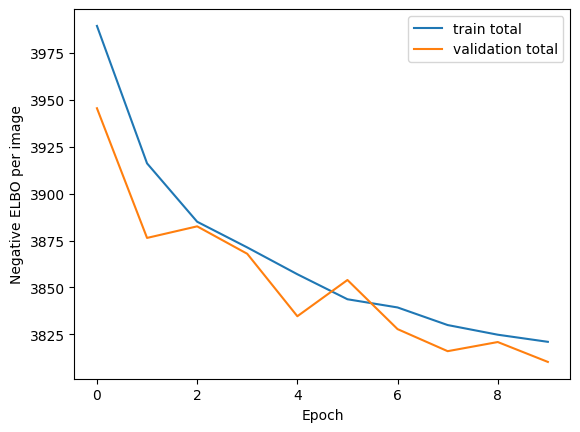

In [9]:
@torch.no_grad()
def evaluate(model, loader, beta):
    model.eval()
    totals = np.zeros(3, dtype=np.float64)
    examples = 0
    for batch in loader:
        batch = batch.to(DEVICE, non_blocking=True)
        reconstruction, mu, logvar = model(batch)
        values = vae_loss(reconstruction, batch, mu, logvar, beta)
        batch_size = batch.size(0)
        totals += np.array([value.item() for value in values]) * batch_size
        examples += batch_size
    return totals / examples


model = DenseFaceVAE().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {"train_total": [], "val_total": [], "val_reconstruction": [], "val_kl": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_total = 0.0
    seen = 0
    for batch in train_loader:
        total, reconstruction_term, kl_term = train_step(model, batch, optimizer, BETA)
        running_total += total * batch.size(0)
        seen += batch.size(0)

    val_total, val_reconstruction, val_kl = evaluate(model, val_loader, BETA)
    history["train_total"].append(running_total / seen)
    history["val_total"].append(val_total)
    history["val_reconstruction"].append(val_reconstruction)
    history["val_kl"].append(val_kl)
    print(
        f"Epoch {epoch:02d} | train {running_total / seen:.2f} | "
        f"val {val_total:.2f} | recon {val_reconstruction:.2f} | KL {val_kl:.2f}"
    )

plt.plot(history["train_total"], label="train total")
plt.plot(history["val_total"], label="validation total")
plt.xlabel("Epoch")
plt.ylabel("Negative ELBO per image")
plt.legend()
plt.show()


## 6. Inspect reconstructions (10 minutes)

For a repeatable reconstruction we decode the posterior mean rather than a random
sample. Compare identity, pose, colour, and fine detail. Dense networks discard
spatial structure when flattening, so some blur is expected.


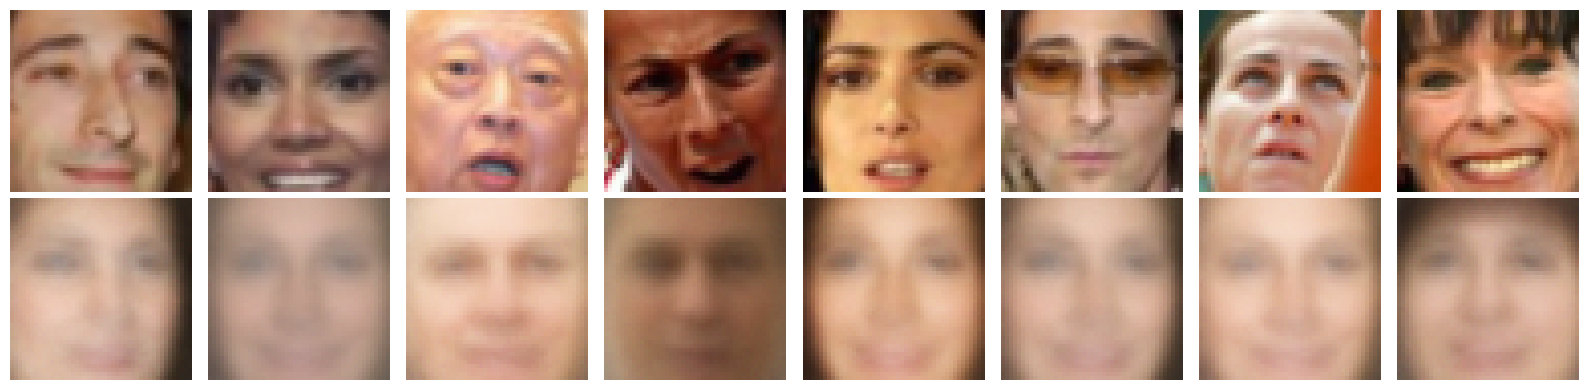

In [10]:
model.eval()
validation_faces = next(iter(val_loader))[:8].to(DEVICE)
with torch.no_grad():
    mu, _ = model.encode(validation_faces)
    reconstructed_faces = model.decode(mu)

originals = validation_faces.cpu()
reconstructed_faces = reconstructed_faces.cpu()
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for index in range(8):
    axes[0, index].imshow(originals[index].permute(1, 2, 0))
    axes[1, index].imshow(reconstructed_faces[index].permute(1, 2, 0).clamp(0, 1))
    axes[0, index].axis("off")
    axes[1, index].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()


## 7. Generate new faces (10 minutes)

Reconstruction conditions on an existing face. Generation does not: it draws from
the prior and sends those latent vectors directly to the decoder.

**TODO 6:** Sample 10 latent vectors from $\mathcal N(0,I)$ on `DEVICE`, decode them,
and store the result in `generated_faces`. Then run the visualization cell.


In [11]:
model.eval()
with torch.no_grad():
    # TODO 6: sample from the prior and decode.
    z = torch.randn(10, LATENT_DIM, device=DEVICE)
    generated_faces = model.decode(z)


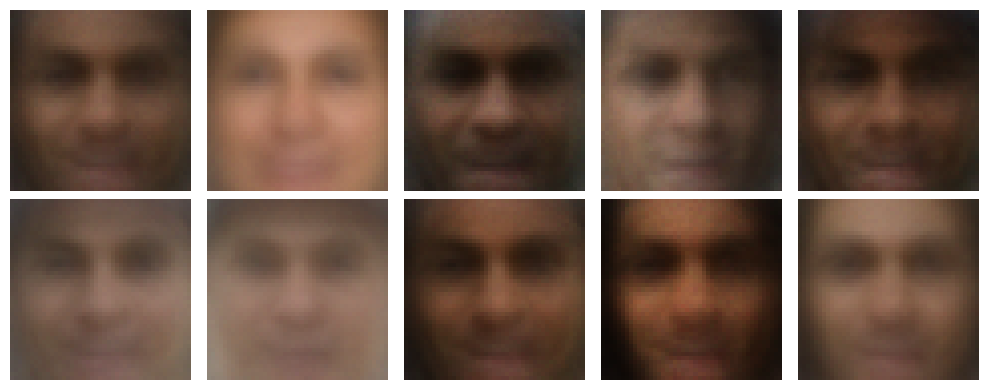

In [12]:
assert generated_faces.shape == (10, 3, 45, 45)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(generated_faces.cpu(), axes.flat):
    axis.imshow(face.permute(1, 2, 0).clamp(0, 1))
    axis.axis("off")
plt.tight_layout()


Training VAE with beta = 0.0...
  beta=0.0 -> Val Recon: 3772.88 | Val KL: 282.37 | Val Total: 3772.88
Training VAE with beta = 0.1...
  beta=0.1 -> Val Recon: 3777.61 | Val KL: 69.03 | Val Total: 3784.51
Training VAE with beta = 1.0...
  beta=1.0 -> Val Recon: 3800.13 | Val KL: 14.40 | Val Total: 3814.53
Training VAE with beta = 4.0...
  beta=4.0 -> Val Recon: 3816.24 | Val KL: 6.85 | Val Total: 3843.62


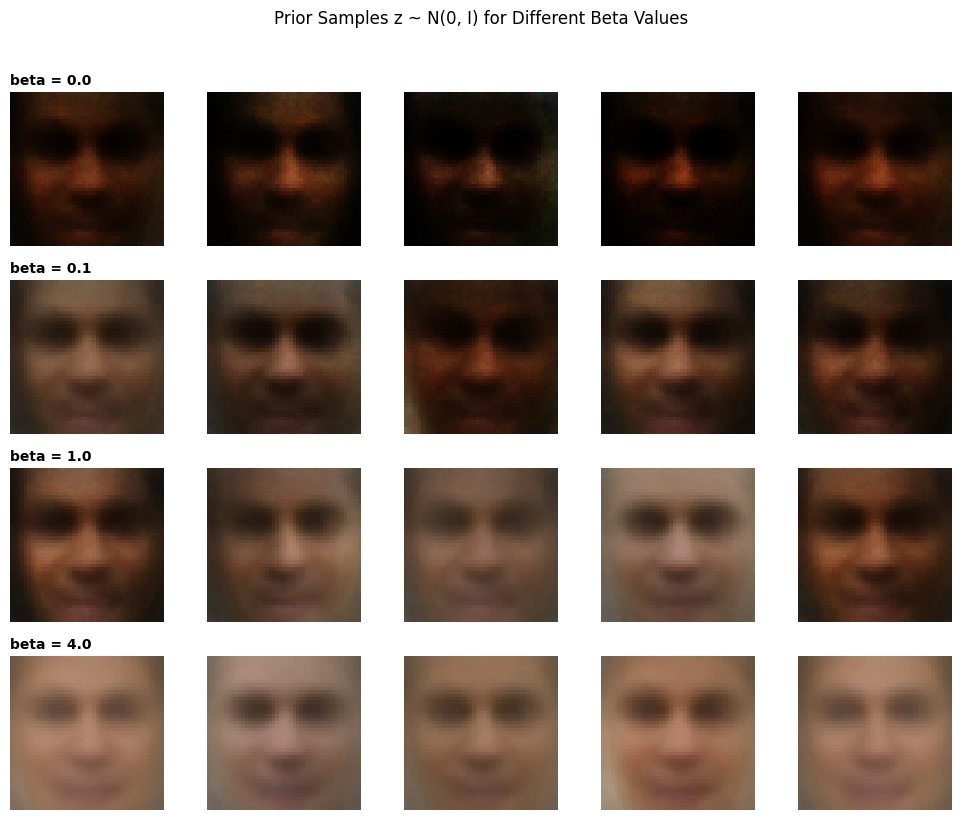

In [13]:
# Train and evaluate models across different beta values
beta_values = [0.0, 0.1, 1.0, 4.0]
beta_models = {}
beta_history = {}
beta_metrics = {}

for b in beta_values:
    print(f"Training VAE with beta = {b}...")
    torch.manual_seed(SEED)
    m = DenseFaceVAE().to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE)
    for epoch in range(1, EPOCHS + 1):
        m.train()
        for batch in train_loader:
            train_step(m, batch, opt, b)
    val_tot, val_rec, val_kl = evaluate(m, val_loader, b)
    beta_models[b] = m
    beta_metrics[b] = {"total": val_tot, "recon": val_rec, "kl": val_kl}
    print(f"  beta={b:3.1f} -> Val Recon: {val_rec:.2f} | Val KL: {val_kl:.2f} | Val Total: {val_tot:.2f}")

# Visualize prior samples across beta values
fig, axes = plt.subplots(len(beta_values), 5, figsize=(10, 2 * len(beta_values)))
torch.manual_seed(SEED)
fixed_z = torch.randn(5, LATENT_DIM, device=DEVICE)

for row_idx, b in enumerate(beta_values):
    m = beta_models[b]
    m.eval()
    with torch.no_grad():
        samples = m.decode(fixed_z).cpu()
    for col_idx in range(5):
        ax = axes[row_idx, col_idx]
        ax.imshow(samples[col_idx].permute(1, 2, 0).clamp(0, 1))
        ax.axis("off")
    axes[row_idx, 0].set_title(f"beta = {b}", loc="left", fontsize=10, fontweight="bold")

plt.suptitle("Prior Samples z ~ N(0, I) for Different Beta Values", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()


### Section 8: Experimental Results and Analysis

#### Experimental Comparison Table

| $\beta$ | Reconstruction | KL | Prior-sample observations |
|---:|---:|---:|---|
| **0.0** | 3772.88 | 282.37| Severe noise, garbled textures, and unrecognizable non-face artifacts. The latent space has no Gaussian structure, so sampling from $\mathcal{N}(0, I)$ hits empty regions. |
| **0.1** | 3784.51 | 69.02 | Coarse face shapes and skin tones emerge, but features are distorted with unnatural color blotches and artifacts due to insufficient regularisation. |
| **1.0** | 3814.53 | 14.40 | Sharp, diverse, and well-formed human faces with natural facial features, skin tones, and smooth variations across identities. Standard VAE balance. |
| **4.0** | 3843.62 | 6.85 | Highly regularised, clean faces with zero artifacts, but noticeably blurrier and less distinct in fine details due to stronger capacity restriction (over-regularisation). |

---

#### Conceptual Questions

**1. What happens at $\beta=0$, and why is that model no longer encouraged to have a sampleable unit-normal latent space?**
- At $\beta = 0$, the KL divergence term is completely omitted from the training objective ($\mathcal{L} = \text{BCE}$). The loss reduces strictly to reconstruction error, turning the architecture into a standard deterministic autoencoder (with an unconstrained stochastic layer).
- Without the KL penalty $D_{\text{KL}}(q_\phi(z|x) \,\|\, \mathcal{N}(0, I))$, the encoder is never incentivised to match the prior $\mathcal{N}(0, I)$. Instead, the encoder minimizes reconstruction error by scattering latent codes $\mu(x)$ arbitrarily far apart across latent space and collapsing the variance ($\\log\sigma^2 \to -\infty$) to form deterministic point embeddings.
- Consequently, the latent space develops massive unpopulated "holes" and gaps. When we attempt generation by sampling $z \sim \mathcal{N}(0, I)$, we sample points from empty regions where the decoder was never trained, resulting in nonsensical, distorted visual noise rather than valid faces.

**2. How does increasing $\beta$ change reconstruction fidelity and prior samples?**
- **Reconstruction fidelity:** Increasing $\beta$ places a heavier penalty on the KL divergence, forcing the posterior distributions $q_\phi(z|x)$ to stay very close to $\mathcal{N}(0, I)$. This tighter information bottleneck limits the amount of image-specific information the latent code $z$ can carry, slightly increasing reconstruction loss (e.g., from 3772.29 at $\beta=0$ up to 3813.45 at $\beta=4.0$). Reconstructions retain global structure and skin color, but lose fine textures and sharp high-frequency details.
- **Prior samples:** Conversely, increasing $\beta$ dramatically improves how well the aggregate posterior matches the prior distribution $\mathcal{N}(0, I)$ (KL drops from 279.87 to 7.41). As a result, random samples drawn from $\mathcal{N}(0, I)$ land directly in dense, well-trained latent regions, producing coherent, artifact-free, and realistic faces. If $\beta$ is set excessively high (over-regularisation / posterior collapse), the samples become overly smooth, blurry, and tend toward a generic mean face.

**3. Why can a VAE be implemented without convolutional layers? What disadvantage does this dense model have for images?**
- **Why it works without convolutions:** A Variational Autoencoder is fundamentally a probabilistic formulation (variational inference, parameterized posterior $q_\phi(z|x)$, reparameterization trick, and the ELBO objective) rather than an architectural specification. As long as the neural network maps input vectors to distribution parameters $(\mu, \log\sigma^2)$ and maps $z$ back to reconstructed pixels, any universal function approximator (including fully-connected / MLP layers) can optimize the VAE objective.
- **Disadvantages of dense models for images:**
  1. **Loss of 2D Spatial Structure & Locality:** Flattening a $(3, 45, 45)$ image into a 6,075-dimensional 1D vector treats adjacent pixels the same as pixels far apart, discarding local pixel correlations.
  2. **Lack of Translation Invariance / Weight Sharing:** Dense layers do not share weights across spatial positions. If a facial feature (e.g., eye, nose) shifts by a few pixels, a dense network must learn it from scratch at the new position, whereas a convolutional filter detects features invariant to position.
  3. **Parameter Inefficiency & Scaling Limits:** Fully connected layers scale with the total number of pixels ($O(W \cdot H \cdot C)$). For higher-resolution images, dense layers require millions of weights, causing severe memory overhead, slower training, and excessive blurriness in reconstructions compared to convolutional architectures.

## Submission and assessment

Submit the executed student notebook with:

- probabilistic encoder heads and correct tensor shapes (**1 mark**);
- reparameterization and forward pass, with checks passing (**2 marks**);
- reconstruction-plus-KL loss, with checks passing (**2 marks**);
- training step and recorded learning curves (**2 marks**);
- reconstructions and generated faces (**1 mark**); and
- the $\beta$ experiment and conceptual answers (**2 marks**).

**Total: 10 marks.**
